In [1]:
from PIL import Image, ImageDraw
import numpy as np
import random
import torch

VOCAB = ['milk', 'wheat', 'soy', 'peanut', 'egg', 'sugar', 'salt', 'water']
NUM_CLASSES = len(VOCAB)

def generate_label_image(word, size=(64, 64)):
    img = Image.new('L', size, color=255)
    draw = ImageDraw.Draw(img)
    draw.text((5, 25), word, fill=0)
    return np.array(img, dtype=np.float32) / 127.5 - 1  # normalize to [-1, 1]

N = 3000
images, labels = [], []
for _ in range(N):
    idx = random.randint(0, NUM_CLASSES - 1)
    images.append(generate_label_image(VOCAB[idx]))
    labels.append(idx)

images = np.array(images)
labels = np.array(labels)
print(f"Generated {N} images, shape: {images.shape}")

Generated 3000 images, shape: (3000, 64, 64)


In [2]:
from torch.utils.data import Dataset, DataLoader

class LabelImgDataset(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        img = torch.tensor(self.images[idx]).unsqueeze(0)  # (1, 64, 64)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return img, label

loader = DataLoader(LabelImgDataset(images, labels), batch_size=64, shuffle=True)

In [3]:
import torch.nn as nn

Z_DIM = 100

class Generator(nn.Module):
    def __init__(self, z_dim=Z_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        self.label_emb = nn.Embedding(num_classes, num_classes)
        self.net = nn.Sequential(
            nn.Linear(z_dim + num_classes, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 64*64), nn.Tanh()
        )
    def forward(self, z, labels):
        c = self.label_emb(labels)
        x = torch.cat([z, c], dim=1)
        return self.net(x).view(-1, 1, 64, 64)

class Discriminator(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.label_emb = nn.Embedding(num_classes, num_classes)
        self.net = nn.Sequential(
            nn.Linear(64*64 + num_classes, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1), nn.Sigmoid()
        )
    def forward(self, img, labels):
        c = self.label_emb(labels)
        x = torch.cat([img.view(img.size(0), -1), c], dim=1)
        return self.net(x)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
G = Generator().to(device)
D = Discriminator().to(device)

In [4]:
criterion = nn.BCELoss()
opt_G = torch.optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=0.0002, betas=(0.5, 0.999))

g_losses, d_losses = [], []
EPOCHS = 60

for epoch in range(EPOCHS):
    g_loss_epoch, d_loss_epoch = 0, 0
    for imgs, labels_batch in loader:
        imgs, labels_batch = imgs.to(device), labels_batch.to(device)
        bs = imgs.size(0)
        real_y = torch.ones(bs, 1).to(device)
        fake_y = torch.zeros(bs, 1).to(device)

        # Train Discriminator
        opt_D.zero_grad()
        d_real = D(imgs, labels_batch)
        loss_real = criterion(d_real, real_y)

        z = torch.randn(bs, Z_DIM).to(device)
        fake_labels = torch.randint(0, NUM_CLASSES, (bs,)).to(device)
        fake_imgs = G(z, fake_labels)
        d_fake = D(fake_imgs.detach(), fake_labels)
        loss_fake = criterion(d_fake, fake_y)

        d_loss = loss_real + loss_fake
        d_loss.backward()
        opt_D.step()

        # Train Generator
        opt_G.zero_grad()
        d_fake_for_g = D(fake_imgs, fake_labels)
        g_loss = criterion(d_fake_for_g, real_y)
        g_loss.backward()
        opt_G.step()

        g_loss_epoch += g_loss.item()
        d_loss_epoch += d_loss.item()

    g_losses.append(g_loss_epoch / len(loader))
    d_losses.append(d_loss_epoch / len(loader))
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}: G_loss={g_losses[-1]:.4f}, D_loss={d_losses[-1]:.4f}")

Epoch 10: G_loss=0.7383, D_loss=1.4303
Epoch 20: G_loss=0.6945, D_loss=1.4100
Epoch 30: G_loss=0.6882, D_loss=1.4038
Epoch 40: G_loss=0.7216, D_loss=1.3830
Epoch 50: G_loss=0.7297, D_loss=1.3786
Epoch 60: G_loss=0.7075, D_loss=1.3885


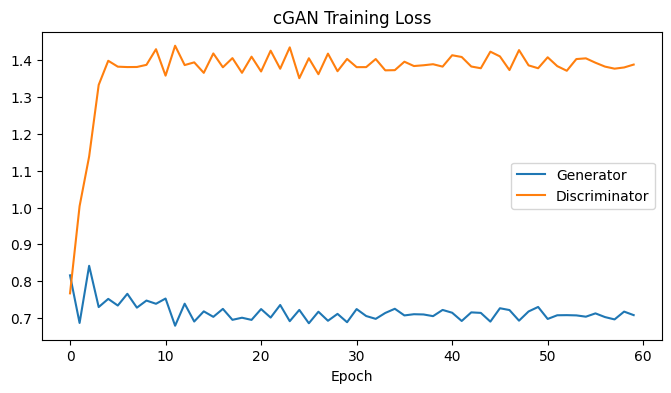

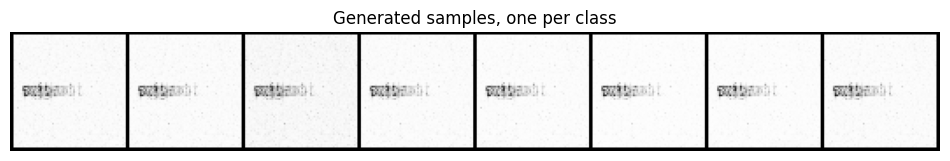

In [5]:
import matplotlib.pyplot as plt
import torchvision.utils as vutils

# Loss curves
plt.figure(figsize=(8,4))
plt.plot(g_losses, label='Generator')
plt.plot(d_losses, label='Discriminator')
plt.legend(); plt.title('cGAN Training Loss'); plt.xlabel('Epoch')
plt.savefig('gan_loss.png', dpi=150); plt.show()

# Sample grid — one row per class
G.eval()
with torch.no_grad():
    z = torch.randn(NUM_CLASSES, Z_DIM).to(device)
    class_labels = torch.arange(NUM_CLASSES).to(device)
    samples = G(z, class_labels).cpu()
    samples = (samples + 1) / 2  # back to [0,1]

grid = vutils.make_grid(samples, nrow=NUM_CLASSES, padding=2)
plt.figure(figsize=(12,3))
plt.imshow(grid.permute(1,2,0).squeeze(), cmap='gray')
plt.axis('off')
plt.title('Generated samples, one per class')
plt.savefig('gan_samples.png', dpi=150); plt.show()